# Scalar mode solver examples

Each section builds a refractive-index profile, plots it, and passes the Cartesian index to `ScalarModeSolver`. `calculate_modes` solves on that grid. `resample_modes` interpolates the stored fields onto another window without solving again.


In [2]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from matplotlib.patches import Circle
from IPython.display import display
from ipywidgets import IntSlider, Output

_start = Path.cwd().resolve()
for _folder in (_start, *_start.parents):
    if (_folder / "fibremodes" / "solvers" / "scalarmodesolver.py").is_file():
        _algorithms = _folder
        break
    if _folder.name == "fibremodes" and (_folder / "solvers" / "scalarmodesolver.py").is_file():
        _algorithms = _folder.parent
        break
    if (_folder / "algorithms" / "fibremodes" / "solvers" / "scalarmodesolver.py").is_file():
        _algorithms = _folder / "algorithms"
        break
else:
    raise RuntimeError("Could not find the fibremodes package from the notebook working directory.")
if str(_algorithms) not in sys.path:
    sys.path.insert(0, str(_algorithms))

from fibremodes.solvers import DoubleClad, GradedIndex, ScalarModeSolver, StepIndex


def complex_to_rgb(field):
    amplitude = np.abs(field)
    amplitude = amplitude / max(float(amplitude.max()), 1e-30)
    hue = (np.angle(field) + np.pi) / (2.0 * np.pi)
    hsv = np.stack([hue, np.ones_like(hue), amplitude], axis=-1)
    return hsv_to_rgb(hsv)


def show_modes(solver, fields, radii):
    axis = solver.x_resampled if fields is solver.modes_resampled else solver.x
    window = float(axis[-1])
    extent = [-window * 1e6, window * 1e6, -window * 1e6, window * 1e6]
    xs_um = axis * 1e6
    cy = fields.shape[1] // 2
    with plt.ioff():
        fig, axes = plt.subplots(nrows=1, ncols=2, gridspec_kw={"width_ratios": [1, 1]})
    fig.set_size_inches(10, 5)

    (line,) = axes[0].plot(xs_um, np.abs(fields[0, cy, :]), color="black")
    axes[0].set_xlabel("x (µm)", fontsize=12)
    axes[0].set_ylabel("|E|", fontsize=12)
    axes[0].grid(visible=True, which="both", linestyle="--", linewidth=1)
    image = axes[1].imshow(complex_to_rgb(fields[0]), extent=extent, origin="lower")
    axes[1].set_xlabel("x (µm)", fontsize=12)
    axes[1].set_ylabel("y (µm)", fontsize=12)
    for radius in radii:
        axes[0].axvline(radius * 1e6, color="0.4", linestyle="--", linewidth=1)
        axes[0].axvline(-radius * 1e6, color="0.4", linestyle="--", linewidth=1)
        if radius <= window:
            axes[1].add_patch(Circle(
                (0, 0), radius * 1e6,
                edgecolor="white", facecolor="none", linewidth=1.2,
            ))

    def update_mode(index):
        field = fields[index]
        cut = np.abs(field[cy, :])
        line.set_ydata(cut)
        peak = float(np.max(cut)) if cut.size else 1.0
        axes[0].set_ylim(0.0, peak * 1.05 if peak > 0.0 else 1.0)
        image.set_data(complex_to_rgb(field))
        axes[0].set_title(rf"index {index}, $n_{{\mathrm{{eff}}}}={solver.n_eff[index]:.5f}$", fontsize=14)
        axes[1].set_title(rf"index {index}", fontsize=14)
        with output:
            output.clear_output(wait=True)
            display(fig)

    output = Output()
    slider = IntSlider(min=0, max=len(fields) - 1, step=1, value=0, description="mode")
    slider.observe(lambda change: update_mode(change["new"]), names="value")
    display(slider, output)
    update_mode(0)


## Step index

Core diameter 50 µm, `n_core = 1.4585`, `NA = 0.22`, wavelength 1.55 µm.


In [6]:
step = StepIndex(core_radius=25e-6, r_max=40e-6, n_core=1.4585, na=0.22, wavelength=1.55e-6)
x, n = step.index_2d()
n.shape

(114, 114)

In [8]:
x, n = step.index_1d()
n.shape

(57,)

Estimated number of modes: 125
Total guided modes: 125
125 guided modes, n_eff from 1.45832 to 1.44200


IntSlider(value=0, description='mode', max=124)

Output()

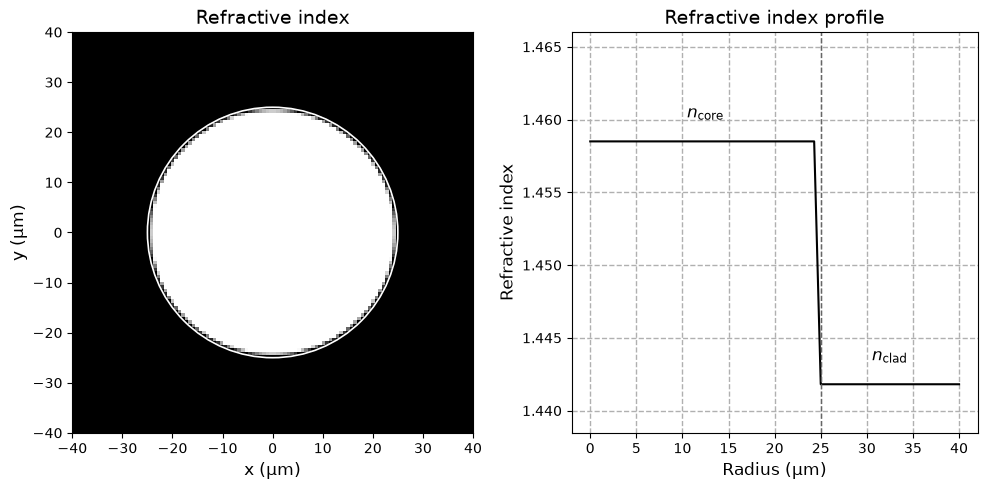

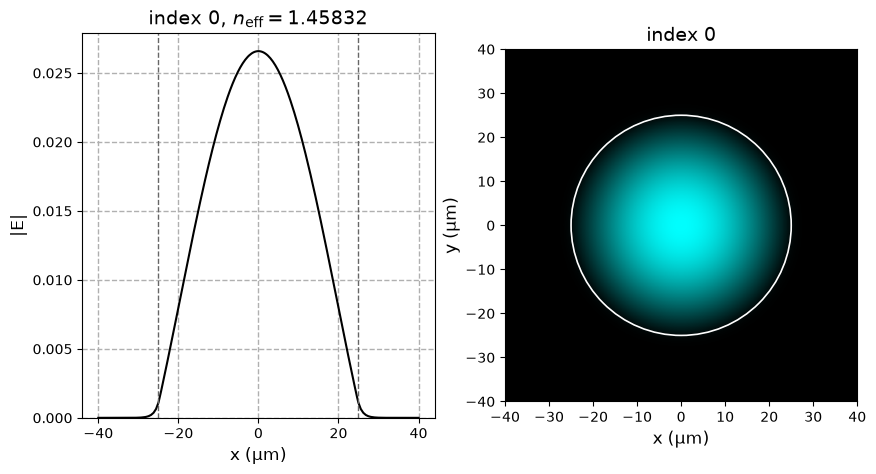

In [ ]:
step = StepIndex(core_radius=25e-6, r_max=40e-6, n_core=1.4585, na=0.22, wavelength=1.55e-6)
x, n = step.index_2d(N=128)
step.plot()
K = step.estimate_num_modes(wav_nm=1550)
solver = ScalarModeSolver(x, n, wavelength=1.55e-6, n_modes=K)
modes = solver.calculate_modes()
resampled = solver.resample_modes(N=256)
print(f"{len(solver.n_eff)} guided modes, n_eff from {solver.n_eff[0]:.5f} to {solver.n_eff[-1]:.5f}")
show_modes(solver, resampled, step.boundary_radii())


## Graded index

Parabolic core of radius 31.25 µm, `n_core = 1.4666`, `NA = 0.275`, `alpha = 2`, wavelength 1565 nm.


In [ ]:
graded = GradedIndex(
    core_radius=31.25e-6, r_max=50e-6, n_core=1.4666, na=0.275, alpha=2,
    wavelength=1565e-9,
)
x, n = graded.index_2d(N=128)
graded.plot()
K = graded.estimate_num_modes(wav_nm=1565)
solver = ScalarModeSolver(x, n, wavelength=1565e-9, n_modes=K)
modes = solver.calculate_modes()
resampled = solver.resample_modes(N=256)
print(f"{len(solver.n_eff)} guided modes, n_eff from {solver.n_eff[0]:.5f} to {solver.n_eff[-1]:.5f}")
show_modes(solver, resampled, graded.boundary_radii())


## Double clad

Diameters 4 µm, 23 µm and the stored curve stops at twice the inner-cladding radius. `n_core = 1.45841`, `NA_core = 0.13`, `NA_clad1 = 0.2`. Wavelength 843.5 nm.


In [ ]:
r_clad1 = 23e-6 / 2
double_clad = DoubleClad(
    core_radius=4e-6 / 2,
    clad1_radius=r_clad1,
    r_max=r_clad1 * 2,
    n_core=1.45841,
    na_core=0.13,
    na_clad1=0.2,
    wavelength=843.5e-9,
)
x, n = double_clad.index_2d(N=128)
double_clad.plot()
K = double_clad.estimate_num_modes(wav_nm=843.5)
solver = ScalarModeSolver(x, n, wavelength=843.5e-9, n_modes=K)
modes = solver.calculate_modes()
resampled = solver.resample_modes(N=256)
print(f"{len(solver.n_eff)} guided modes, n_eff from {solver.n_eff[0]:.5f} to {solver.n_eff[-1]:.5f}")
show_modes(solver, resampled, double_clad.boundary_radii())


In [ ]:
wide = solver.resample_modes(N=256, window_max=100e-6)
print(f"resampled axis from {solver.x_resampled[0]*1e6:.0f} µm to {solver.x_resampled[-1]*1e6:.0f} µm, N = {len(solver.x_resampled)}")
print(f"solve grid unchanged: {solver.modes.shape}")
show_modes(solver, wide, double_clad.boundary_radii())
